# 02 · Manifold — principal-curve trajectory

Fit a scFates principal **curve** (non-branching topology: Gast/pSom co-vary rather
than diverge into competing arms), root at the developmental origin (Gast/pSom-high,
Crest-low tip — Crest is LATE), compute pseudotime, and confirm the fit is fold-free
off an independent diagnostic (not read off the embedding being tested). Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; confirm one elongated cloud, not two blobs

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
adata

whole malignant manifold: 1091 cells
UMAP aspect ratio (major/minor std): 1.35


### Score the three embryonic modules (union control pool) + graph-smooth

Scores computed here (raw `score_genes`, comparable via the shared union pool) and
graph-smoothed over the kNN connectivities for reading geography; the deliverable
signature panels in 03 show the RAW scores.

In [4]:
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]

Gast: 71/81 genes present
pSom: 86/98 genes present
Crest: 100/104 genes present


### Biology before geometry: one axis, and is cycling a confound?

Gast/pSom co-vary and both oppose Crest (a single axis, not two competing arms); no
module tracks the g2m proliferation score — the developmental axis is orthogonal to
the small cycling pocket, so the whole manifold is kept.

In [5]:
print('smoothed spatial correlations (whole manifold):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]; print(f'  {a} vs {b}: r = {r:+.2f}')
cyc = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
print('proliferation confound (Spearman module vs g2m_score):')
for m in ['Gast', 'pSom', 'Crest']:
    rho, _ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs g2m: rho = {rho:+.2f}')
print('-> Gast/pSom co-vary; both oppose Crest; no module tracks proliferation.')
print('   developmental axis is orthogonal to the cycling pocket -> keep the whole manifold.')
sub = adata

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.66
  Crest_sm vs Gast_sm: r = -0.97
  Crest_sm vs pSom_sm: r = -0.75
proliferation confound (Spearman module vs g2m_score):
  Gast vs g2m: rho = -0.07
  pSom vs g2m: rho = -0.01
  Crest vs g2m: rho = +0.04
-> Gast/pSom co-vary; both oppose Crest; no module tracks proliferation.
   developmental axis is orthogonal to the cycling pocket -> keep the whole manifold.


### Fit a principal CURVE (non-branching) + fold diagnostic

Curve, not tree: Gast/pSom co-vary rather than diverge. The self-approach ratio
(min Euclidean distance between graph-distant nodes / median edge length) is measured
on the fitted graph, independent of the UMAP neighbour structure — >1 means fold-free.
Robust to Nodes 15–30 and mu 50–100 (all 2 tips / 0 forks).

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med, tips, forks
for nodes, mu in [(20, 100.0), (15, 50.0), (25, 75.0), (30, 100.0)]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=mu, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'Nodes={nodes} mu={mu}: {tips} tips, {forks} forks | self-approach ratio = {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free 2-tip curve)'
print(f'final curve (Nodes=20): {tips} tips, {forks} forks, self-approach {sa:.2f} -> non-branching curve confirmed')

Nodes=20 mu=100.0: 2 tips, 0 forks | self-approach ratio = 2.68
Nodes=15 mu=50.0: 2 tips, 0 forks | self-approach ratio = 2.77
Nodes=25 mu=75.0: 2 tips, 0 forks | self-approach ratio = 2.46
Nodes=30 mu=100.0: 2 tips, 0 forks | self-approach ratio = 2.40
final curve (Nodes=20): 2 tips, 0 forks, self-approach 2.68 -> non-branching curve confirmed


### Root at the developmental origin (Gast/pSom-high, Crest-low tip)

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.3f} pSom={info[tp][1]:+.3f} Crest={info[tp][2]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}  p = {p:.1e}')

tip 0: Gast=+0.129 pSom=+0.528 Crest=-0.319
tip 2: Gast=+0.074 pSom=+0.378 Crest=-0.230
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.222  p = 1.3e-13
  pSom_sm: rho = -0.802  p = 2.2e-246
  Crest_sm: rho = +0.353  p = 2.0e-33


### Pseudotime + rename milestones (root / terminus)

milestones: {'0': 'Gast/pSom origin', '2': 'Crest terminus'}


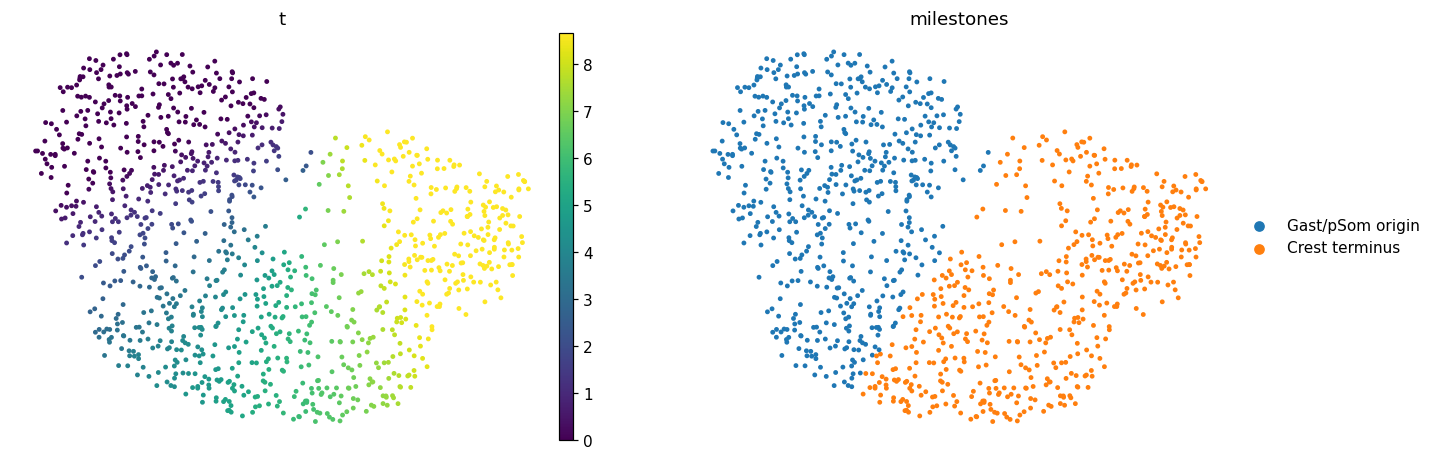

In [8]:
sub.obs['milestones'] = sub.obs['milestones'].astype('category')
ms = sub.obs['milestones'].cat.categories.tolist()
tmean = {m: sub.obs.loc[sub.obs['milestones'] == m, 't'].mean() for m in ms}
newnames = {m: ('Gast/pSom origin' if tmean[m] == min(tmean.values()) else 'Crest terminus') for m in ms}
scf.tl.rename_milestones(sub, new=newnames)
print('milestones:', newnames)
sc.pl.umap(sub, color=['t', 'milestones'], size=40, frameon=False)

### Orientation consistency — reuse house X_umap_lin, verify vs pseudotime

In [9]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:, 0], sub.obs['t'].values)[0, 1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:
    sub.obsm['X_umap_lin'][:, 0] = -sub.obsm['X_umap_lin'][:, 0]; r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.95


### Save manifold + pseudotime figure (deliverable)

saved manifold.h5ad (1091, 18682)
saved manifold.pdf


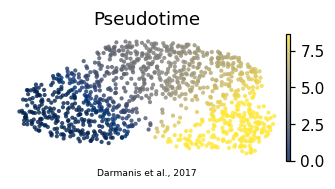

In [10]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Darmanis et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')